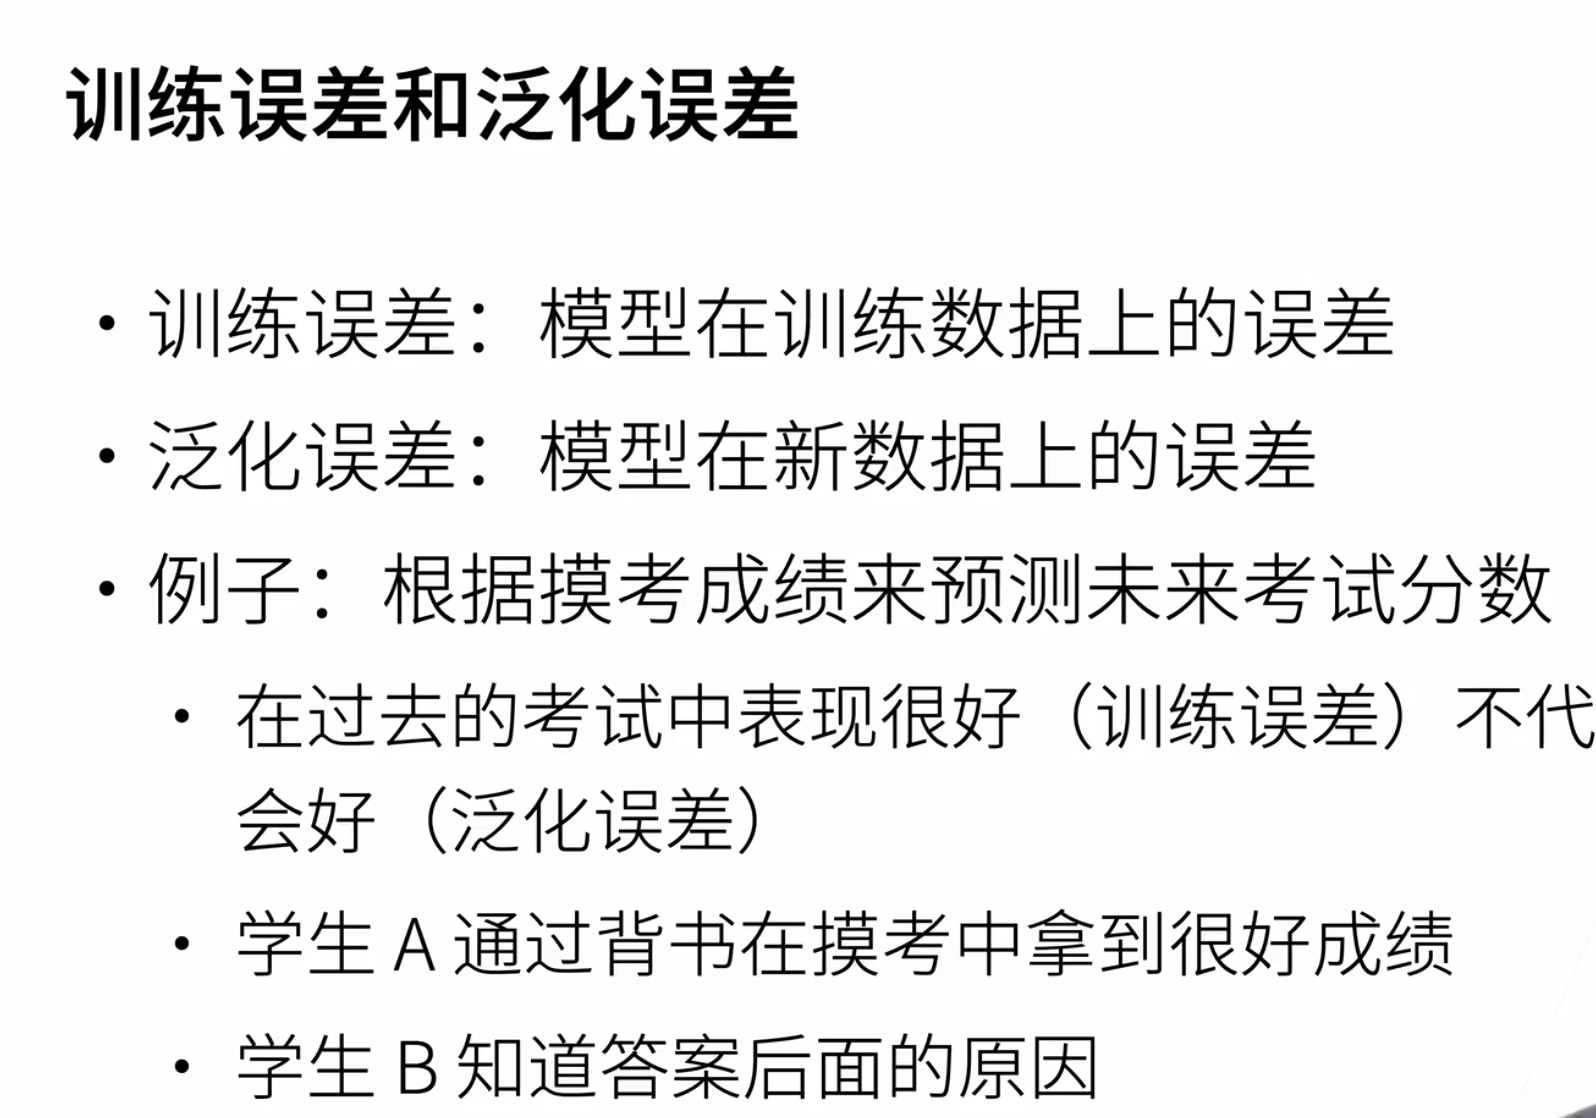

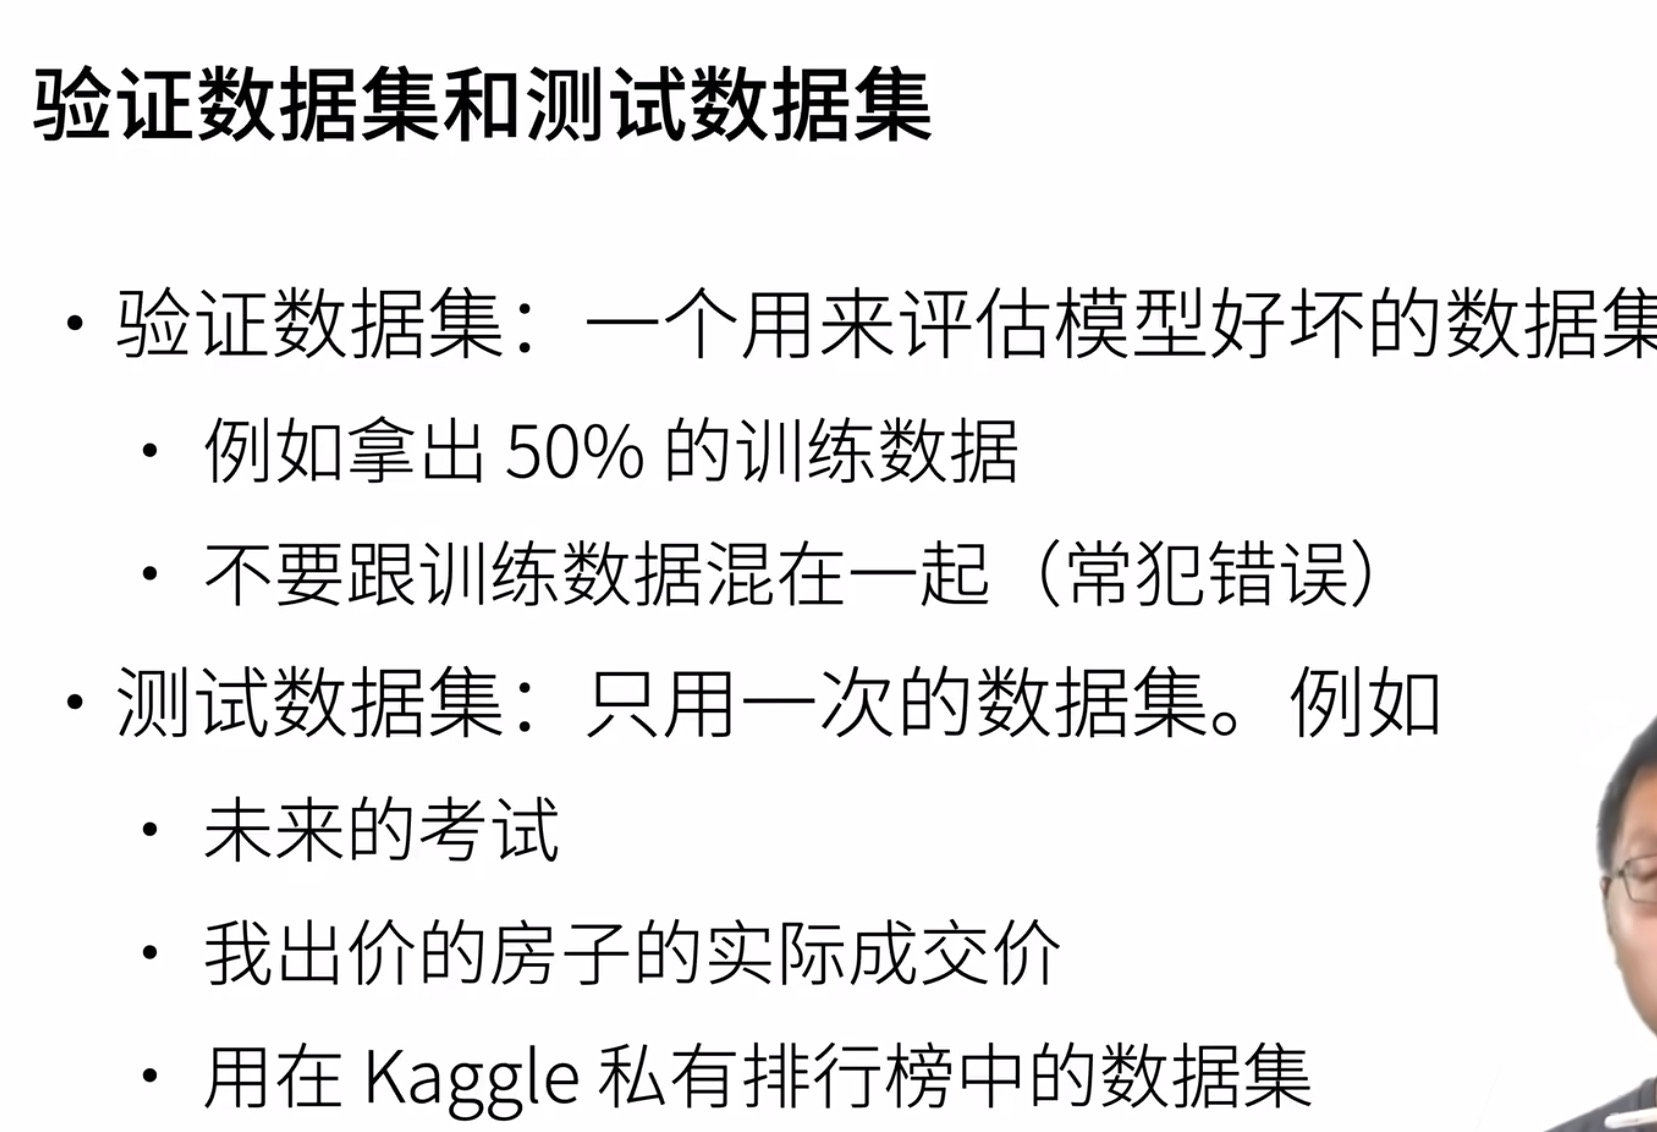

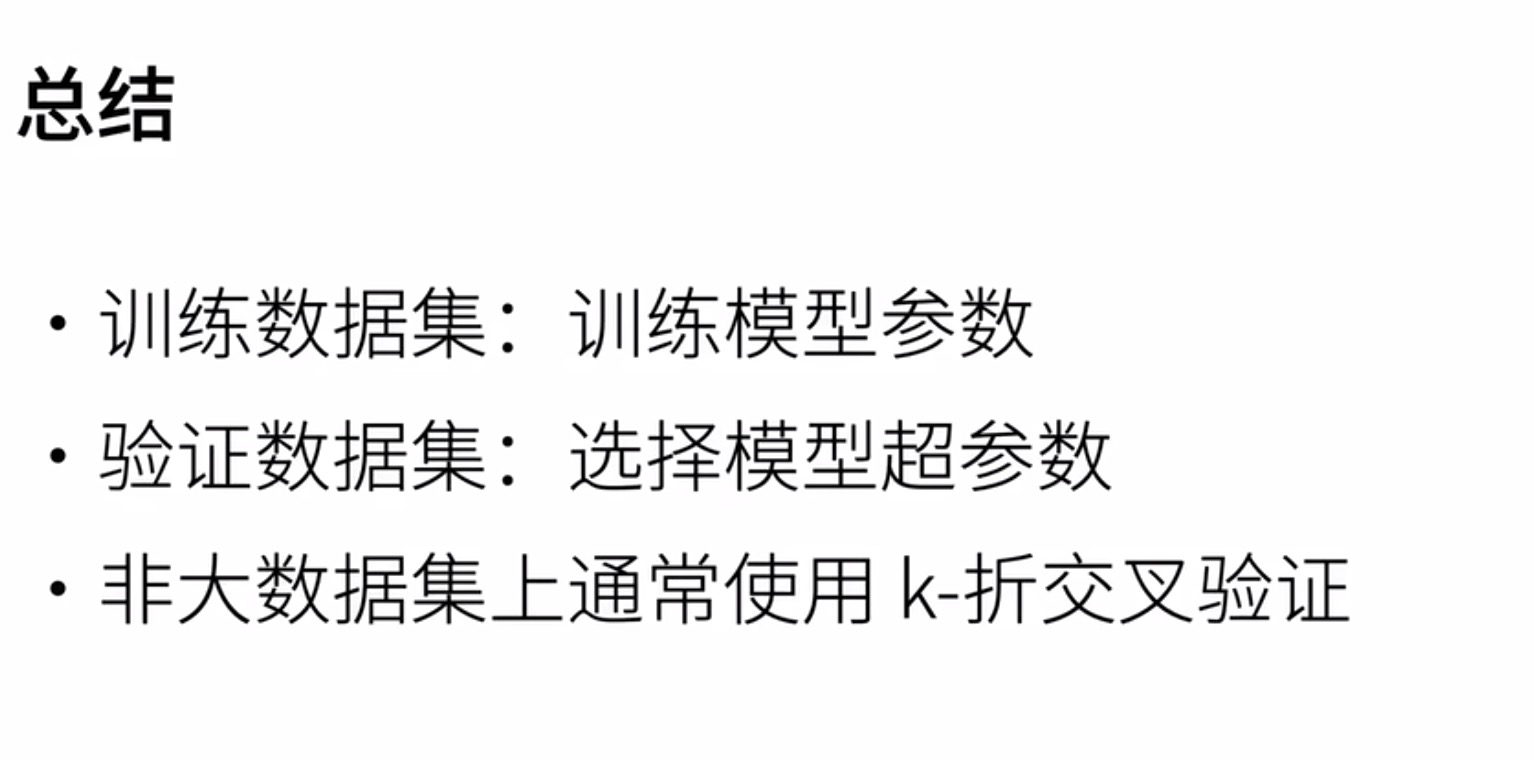

过拟合和欠拟合

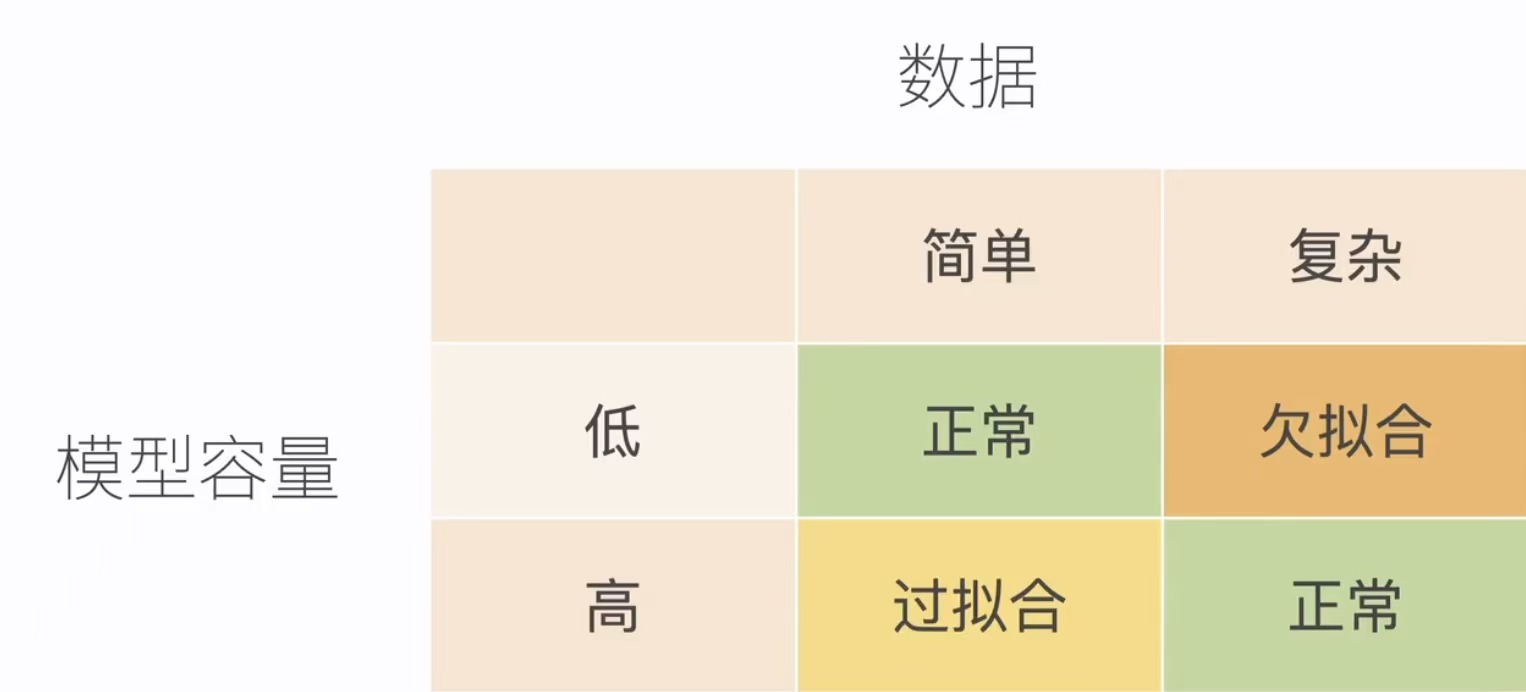

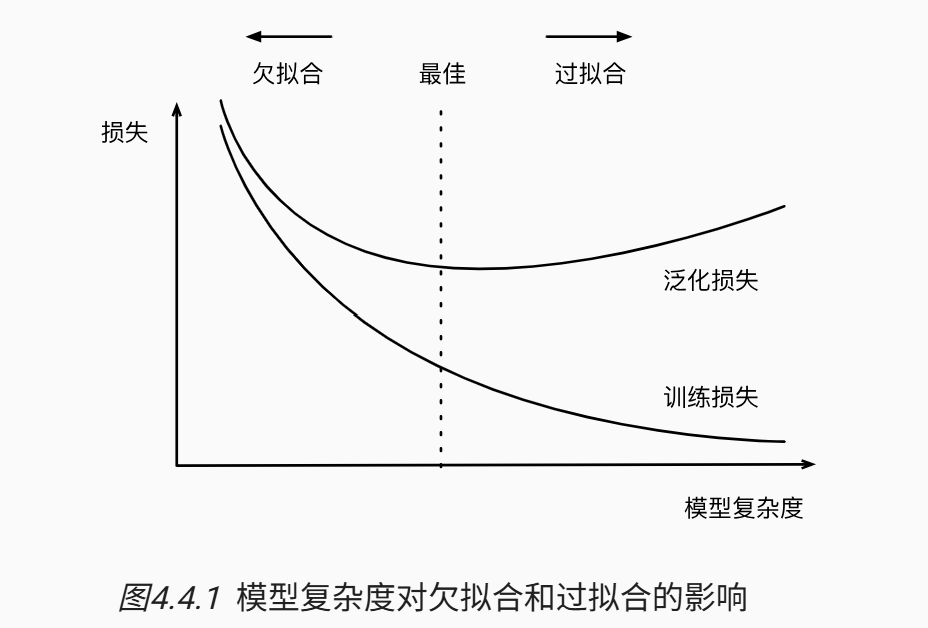

In [2]:
import math
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l

生成数据集

In [4]:
max_degree = 20 # 多项式的最大阶数
n_train, n_test = 100, 100 # 训练和测试数据集大小
true_w = np.zeros(max_degree)
true_w[0:4] = np.array([5, 1.2, -3.4, 5.6])

features = np.random.normal(size=(n_train + n_test, 1))
np.random.shuffle(features)
poly_features = np.power(features, np.arange(max_degree).reshape(1, -1))
for i in range(max_degree):
    poly_features[:,i] /= math.gamma(i + 1)

labels = np.dot(poly_features, true_w)
labels += np.random.normal(scale=0.1, size=labels.shape)


In [5]:
true_w, festures, poly_features,labels = [torch.tensor(x, dtype=torch.float32) for x in [true_w, features, poly_features, labels]]
features[:2], poly_features[:2, :], labels[:2]

(array([[0.46047263],
        [0.02658809]]),
 tensor([[1.0000e+00, 4.6047e-01, 1.0602e-01, 1.6273e-02, 1.8733e-03, 1.7252e-04,
          1.3240e-05, 8.7096e-07, 5.0131e-08, 2.5649e-09, 1.1811e-10, 4.9441e-12,
          1.8972e-13, 6.7200e-15, 2.2103e-16, 6.7851e-18, 1.9527e-19, 5.2893e-21,
          1.3531e-22, 3.2793e-24],
         [1.0000e+00, 2.6588e-02, 3.5346e-04, 3.1326e-06, 2.0823e-08, 1.1073e-10,
          4.9067e-13, 1.8637e-15, 6.1941e-18, 1.8299e-20, 4.8653e-23, 1.1760e-25,
          2.6056e-28, 5.3291e-31, 1.0121e-33, 1.7939e-36, 2.9811e-39, 4.6621e-42,
          7.0065e-45, 0.0000e+00]]),
 tensor([5.2775, 5.1610]))

对模型进行训练和测试
实现一个函数来评估模型在给定数据集上的损失

In [6]:
def evaluate_loss(net, data_iter, loss): #@save
    metric = d2l.Accumulator(2)
    for X, y in data_iter:
        out = net(X)
        y = y.reshape(out.shape)
        l = loss(out,y)
        metric.add(l.sum(), l.numel())
    return metric[0] / metric[1]
    

定义训练函数

In [18]:
def train(train_features, test_features, train_labels, test_labels,
          num_epochs=400):
    loss = nn.MSELoss(reduction='none')
    input_shape = train_features.shape[-1]
    # 不设置偏置，因为我们已经在多项式中实现了它
    net = nn.Sequential(nn.Linear(input_shape, 1, bias=False))
    batch_size = min(10, train_labels.shape[0])
    train_iter = d2l.load_array((train_features, train_labels.reshape(-1,1)),
                                batch_size)
    test_iter = d2l.load_array((test_features, test_labels.reshape(-1,1)),
                               batch_size, is_train=False)
    trainer = torch.optim.SGD(net.parameters(), lr=0.01)
    animator = d2l.Animator(xlabel='epoch', ylabel='loss', yscale='log',
                            xlim=[1, num_epochs], ylim=[1e-3, 1e2],
                            legend=['train', 'test'])
    for epoch in range(num_epochs):
        d2l.train_epoch_ch3(net, train_iter, loss, trainer)
        if epoch == 0 or (epoch + 1) % 20 == 0:
            animator.add(epoch + 1, (evaluate_loss(net, train_iter, loss),
                                     evaluate_loss(net, test_iter, loss)))
    print('weight:', net[0].weight.data.numpy())

三阶多项式函数拟合(正常)

weight: [[ 5.020774   1.3783967 -3.49118    5.068462 ]]


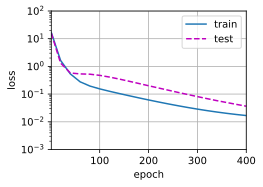

In [19]:
train(poly_features[:n_train, :4], poly_features[n_train:, :4],
      labels[:n_train], labels[n_train:])

线性函数拟合(欠拟合)

weight: [[3.646223 3.549363]]


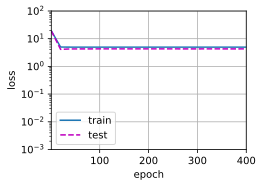

In [21]:
train(poly_features[:n_train, :2], poly_features[n_train:, :2],
    labels[:n_train], labels[n_train:])


高阶多项式函数拟合(过拟合)

weight: [[ 4.9648623e+00  1.2624270e+00 -3.1988554e+00  5.2753215e+00
  -8.4479654e-01  8.4995973e-01 -9.2570946e-02  2.5087619e-02
   1.8914579e-01 -7.3837131e-02 -1.7504527e-01 -7.5607754e-02
   2.0420410e-01 -5.6230284e-02 -1.1695038e-01  4.2082876e-02
   2.2187856e-01  1.2784454e-01 -1.4853328e-03 -8.5962400e-02]]


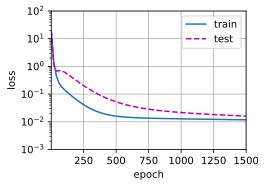

In [23]:
train(poly_features[:n_train, :],poly_features[n_train:, :],
      labels[:n_train], labels[n_train:], num_epochs=1500)